## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from idx_exchange_data_science import preprocessing as pp

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid")

DATA_PATH = Path("../data/intermediate/CRMLSSoldFiltered.csv")
OUT_DIR = Path("../data/processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
raw = pp.load_filtered(DATA_PATH)
raw.shape

(309735, 84)

## 2. Stateless cleaning
These steps look at one row at a time and don't compute anything from the dataset (no means, no counts), so running them before the split doesn't leak anything. Row counts after each step:

In [3]:
df = raw
log = [("loaded", len(df))]
for step in pp.CLEANING_STEPS:
    df = df.pipe(step)
    log.append((step.__name__, len(df)))
pd.DataFrame(log, columns=["step", "rows"]).assign(rows_removed=lambda t: -t["rows"].diff().fillna(0).astype(int))

,step,rows,rows_removed
0,loaded,309735,0
1,parse_dates,309735,0
2,drop_duplicate_listings,309471,264
3,drop_invalid_rows,309161,310
4,standardize_fields,309161,0
5,nullify_implausible,309161,0
6,add_features,309161,0
7,select_columns,309161,0


What each step does (thresholds are in the module CONFIG):

- **`drop_duplicate_listings`**: one row per `ListingKey`, keeping the latest `CloseDate`. The duplicates come from overlapping monthly exports (01_exploration 2.1).
- **`drop_invalid_rows`**: drops rows whose **target** is probably a typo: `ClosePrice` outside \$50K to \$50M, or sale-to-list ratio outside 0.5 to 2. Also drops out-of-state rows. `ListPrice` is only used for this check and is dropped afterwards (leakage).
- **`standardize_fields`**: trims ZIP+4 to 5 digits, keeps the first token of multi-valued `Levels` (e.g. `Two,MultiSplit` becomes `Two`), converts `AssociationFee` to a monthly amount using `AssociationFeeFrequency`, and casts Y/N fields to 1/0 while keeping NaN.
- **`nullify_implausible`**: sets impossible **feature** values to NaN, for example `LivingArea` < 300 sq ft, 0 bedrooms, a 2-billion-sq-ft lot, or coordinates outside California. These are then imputed like any other missing value. That way a single bad field doesn't cost the whole row, and the test month keeps all its rows.
- **`add_features`**: `PropertyAge` = close year − `YearBuilt`.
- **`select_columns`**: keeps only pre-listing features plus the id, date, and target.

Values set to NaN by `nullify_implausible`:

In [4]:
before = raw.pipe(pp.parse_dates).pipe(pp.drop_duplicate_listings).pipe(pp.drop_invalid_rows).pipe(pp.standardize_fields)
after = pp.nullify_implausible(before)
cols = list(pp.PLAUSIBLE_RANGES) + ["MainLevelBedrooms"]
pd.Series({c: int(after[c].isna().sum() - before[c].isna().sum()) for c in dict.fromkeys(cols)}, name="values_nulled").to_frame()

,values_nulled
LivingArea,190
BedroomsTotal,174
BathroomsTotalInteger,146
MainLevelBedrooms,1916
LotSizeSquareFeet,768
GarageSpaces,48
ParkingTotal,318
AssociationFeeMonthly,5
YearBuilt,8
Latitude,37


### Columns dropped
Every column in the filtered file that isn't kept, grouped by reason. Roles come from 01_exploration 2.4.

In [5]:
drop_reasons = {
    "Leakage (only known at or after listing)": [
        "ListPrice", "OriginalListPrice", "DaysOnMarket", "ListingContractDate", "PurchaseContractDate",
        "ContractStatusChangeDate", "ListOfficeName", "CoListOfficeName", "BuyerOfficeName",
        "ListAgentAOR", "BuyerAgentAOR", "BuyerOfficeAOR", "BuyerAgencyCompensation", "BuyerAgencyCompensationType",
    ],
    "PII": [
        "ListAgentEmail", "ListAgentFirstName", "ListAgentLastName", "ListAgentFullName", "CoListAgentFirstName",
        "CoListAgentLastName", "BuyerAgentMlsId", "BuyerAgentFirstName", "BuyerAgentLastName", "CoBuyerAgentFirstName",
    ],
    "Identifier, not a property attribute": ["ListingKeyNumeric", "ListingId", "UnparsedAddress", "StreetNumberNumeric"],
    "Empty or >93% missing": [
        "FireplacesTotal", "AboveGradeFinishedArea", "CoveredSpaces", "ElementarySchoolDistrict",
        "MiddleOrJuniorSchoolDistrict", "TaxAnnualAmount", "TaxYear", "BelowGradeFinishedArea", "BusinessType",
        "WaterfrontYN", "BuildingAreaTotal", "LotSizeDimensions", "BuilderName",
    ],
    "82-86% missing, and HighSchoolDistrict already covers the school area": ["ElementarySchool", "MiddleOrJuniorSchool", "HighSchool"],
    "65% missing, ~12K messy free-text levels; PostalCode/City cover location": ["SubdivisionName"],
    "Constant after filters": ["MlsStatus", "PropertyType", "PropertySubType", "StateOrProvince"],
    "Source-system metadata, not a property attribute": ["OriginatingSystemName", "OriginatingSystemSubName", "latfilled", "lonfilled"],
    "Redundant (same info as a kept column)": ["LotSizeAcres", "LotSizeArea", "Stories"],
    "Replaced by a derived column": ["YearBuilt", "Levels", "AssociationFee", "AssociationFeeFrequency"],
    "Multi-valued free text, written at listing time (candidate to revisit)": ["Flooring"],
}
listed = [c for cols in drop_reasons.values() for c in cols]
unaccounted = set(raw.columns) - set(listed) - set(pp.KEEP_COLS)
assert not unaccounted, unaccounted
pd.DataFrame([(r, ", ".join(c)) for r, c in drop_reasons.items()], columns=["reason", "columns"])

,reason,columns
0,Leakage (only known at or after listing),"ListPrice, OriginalListPrice, DaysOnMarket, Li..."
1,PII,"ListAgentEmail, ListAgentFirstName, ListAgentL..."
2,"Identifier, not a property attribute","ListingKeyNumeric, ListingId, UnparsedAddress,..."
3,Empty or >93% missing,"FireplacesTotal, AboveGradeFinishedArea, Cover..."
4,"82-86% missing, and HighSchoolDistrict already...","ElementarySchool, MiddleOrJuniorSchool, HighSc..."
5,"65% missing, ~12K messy free-text levels; Post...",SubdivisionName
6,Constant after filters,"MlsStatus, PropertyType, PropertySubType, Stat..."
7,"Source-system metadata, not a property attribute","OriginatingSystemName, OriginatingSystemSubNam..."
8,Redundant (same info as a kept column),"LotSizeAcres, LotSizeArea, Stories"
9,Replaced by a derived column,"YearBuilt, Levels, AssociationFee, Association..."


Notes:
- `LotSizeAcres` and `LotSizeSquareFeet` agree on 99.9% of rows, and `LotSizeArea` uses mixed units (01_exploration 2.3), so only `LotSizeSquareFeet` is kept.
- `Stories` is a copy of `Levels` (every `Stories` value lines up with a `Levels` value), and `Levels` is more complete and more detailed.
- `latfilled` / `lonfilled` came from an unknown upstream fill step. Coordinates are kept, and missing coordinates get their own flag below.

## 3. Missing values
The plan for each kept feature column. Everything here is **fit on the training window** inside `pp.Preprocessor`. Missing rates are for the whole cleaned dataset:

In [6]:
strategy = {
    **{c: ("Impute median", "<0.3% missing; too rare to carry information") for c in pp.IMPUTE_MEDIAN},
    **{c: ("Impute median + flag", "1-40% missing; whether it was reported may carry signal") for c in pp.IMPUTE_MEDIAN_FLAG},
    **{c: ("Impute 0 + flag", "a blank fee most likely means no HOA; the flag keeps the difference") for c in pp.IMPUTE_ZERO_FLAG},
    **{c: ("Impute mode + flag", "NaN group's median price differs a lot from True/False (below)") for c in pp.IMPUTE_MODE_FLAG},
    **{c: ("Impute 0", "only True is ever recorded, so blank means no basement") for c in pp.IMPUTE_ZERO},
    **{c: ("Impute ZIP median -> county -> overall, + flag", "nearby homes have similar coordinates; a global median would put homes in the wrong place") for c in pp.IMPUTE_GEO},
    **{c: ("'Missing' category", "missing becomes its own level, which works like a flag") for c in pp.ONE_HOT_COLS + pp.TARGET_ENCODE_COLS},
}
feature_cols = [c for c in pp.KEEP_COLS if c not in (pp.ID_COL, pp.DATE_COL, pp.TARGET)]
assert set(strategy) == set(feature_cols)
(
    pd.DataFrame(strategy, index=["strategy", "why"]).T
    .assign(pct_missing=df[feature_cols].isna().mean().mul(100).round(2))
    .sort_values("pct_missing", ascending=False)
)

,strategy,why,pct_missing
BasementYN,Impute 0,"only True is ever recorded, so blank means no ...",97.600
MainLevelBedrooms,Impute median + flag,1-40% missing; whether it was reported may car...,40.940
AssociationFeeMonthly,Impute 0 + flag,a blank fee most likely means no HOA; the flag...,30.250
HighSchoolDistrict,'Missing' category,"missing becomes its own level, which works lik...",26.070
MLSAreaMajor,'Missing' category,"missing becomes its own level, which works lik...",14.220
AttachedGarageYN,Impute mode + flag,NaN group's median price differs a lot from Tr...,11.620
PoolPrivateYN,Impute mode + flag,NaN group's median price differs a lot from Tr...,9.630
LevelsPrimary,'Missing' category,"missing becomes its own level, which works lik...",9.450
ViewYN,Impute mode + flag,NaN group's median price differs a lot from Tr...,8.930
NewConstructionYN,Impute mode + flag,NaN group's median price differs a lot from Tr...,7.270


**Why drop no rows for missing features:** `ClosePrice` has no missing values, and every feature is either imputed or flagged. Dropping rows would also remove test-month homes, and an AVM still has to give a value for a home with an incomplete listing.

**Why flag the Y/N fields:** in 01_exploration 3.3 the NaN group had a very different median price from both True and False (e.g. `PoolPrivateYN`: NaN \$1.71M vs False \$0.82M vs True \$1.12M). Same check on the cleaned data:

In [7]:
pd.concat(
    {c: df.groupby(df[c].map({1.0: "True", 0.0: "False"}).fillna("NaN"))[pp.TARGET].median() for c in pp.BOOL_COLS},
    axis=1,
).T.map("${:,.0f}".format)

,False,NaN,True
NewConstructionYN,"$895,000","$995,000","$648,390"
AttachedGarageYN,"$885,000","$885,000","$899,000"
PoolPrivateYN,"$820,000","$1,710,000","$1,115,000"
ViewYN,"$865,000","$950,000","$905,000"
FireplaceYN,"$715,000","$1,435,000","$1,005,000"


Missing rates are steady from month to month (01_exploration 2.2), with one exception: February 2024 is missing about 25% of its coordinates. ZIP-level filling handles that, and `Coords_was_missing` marks those rows.

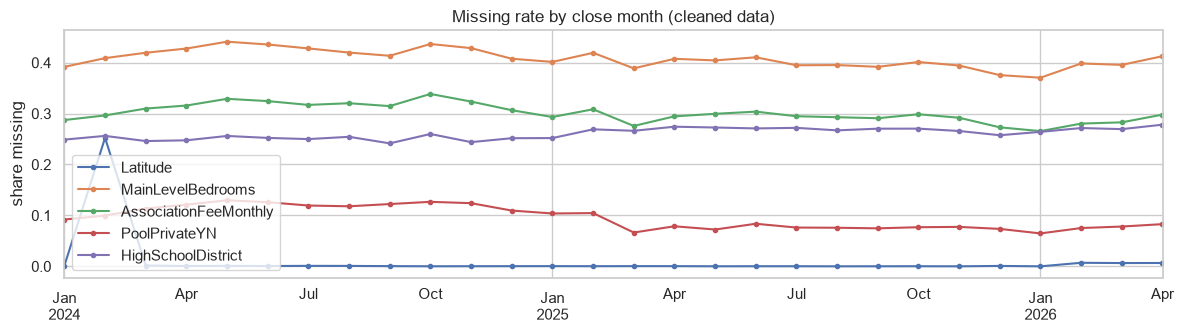

In [8]:
miss_by_month = df[["Latitude", "MainLevelBedrooms", "AssociationFeeMonthly", "PoolPrivateYN", "HighSchoolDistrict"]].isna().groupby(pp.close_month(df)).mean()
ax = miss_by_month.plot(figsize=(12, 3.5), marker="o", markersize=3)
ax.set(title="Missing rate by close month (cleaned data)", ylabel="share missing", xlabel="")
plt.tight_layout()

## 4. Encoding categorical fields
| Column | Levels | Method | Why |
|---|---|---|---|
| `CountyOrParish` | ~58 | One-hot. Counties with fewer than 200 training rows go into one "infrequent" column | Nominal, few enough levels |
| `LevelsPrimary` | 4 + Missing | One-hot | Nominal. `MultiSplit` doesn't fit cleanly on an ordinal scale |
| `PostalCode` | ~1,800 | Target encoding | High cardinality; strongest location signal |
| `City` | ~1,000 | Target encoding | High cardinality |
| `MLSAreaMajor` | ~1,000 | Target encoding | High cardinality |
| `HighSchoolDistrict` | ~440 | Target encoding | High cardinality; school quality affects price |
| Y/N fields | 2 | 1/0 | Already binary |

**Target encoding details (sklearn `TargetEncoder`):** each category is replaced by its smoothed mean of **log** `ClosePrice` in the training window. Rare categories are pulled toward the overall mean. On training rows the encoding is cross-fitted (5 folds), so a row's own price never goes into its own encoding. Without that, the model would overfit to the encoding. Categories not seen in training get the overall mean.

Example on one window (train = 6 months before 2026-03):

In [9]:
train_ex, test_ex = pp.time_split(df, test_month="2026-03", train_months=6)
pre_ex = pp.Preprocessor(scale=False)
train_ex_p = pre_ex.fit_transform(train_ex)
test_ex_p = pre_ex.transform(test_ex)

print(f"train {len(train_ex):,} rows, test {len(test_ex):,} rows, {len(pre_ex.feature_names_)} features")
print("NaNs left in features:", int(train_ex_p[pre_ex.feature_names_].isna().sum().sum()), "/", int(test_ex_p[pre_ex.feature_names_].isna().sum().sum()))
for col in pp.TARGET_ENCODE_COLS:
    unseen = ~test_ex[col].fillna(pp.MISSING_CATEGORY).isin(set(train_ex[col].fillna(pp.MISSING_CATEGORY)))
    print(f"{col:20s} levels in train: {train_ex[col].nunique():5d}   test rows with unseen level: {unseen.mean():.2%}")

train 60,004 rows, test 11,547 rows, 59 features
NaNs left in features: 0 / 0
PostalCode           levels in train:  1302   test rows with unseen level: 0.23%
City                 levels in train:   898   test rows with unseen level: 0.18%
MLSAreaMajor         levels in train:   977   test rows with unseen level: 0.10%
HighSchoolDistrict   levels in train:   397   test rows with unseen level: 0.05%


In [10]:
train_ex_p[[pp.ID_COL, "PostalCode_te", "City_te", pp.LOG_TARGET]].head()

,ListingKey,PostalCode_te,City_te,LogClosePrice
0,1131119149,13.897,13.833,13.780
1,1131118385,15.147,14.174,15.320
2,1131056397,13.908,13.898,14.328
3,1125688828,13.358,13.228,13.271
4,1117686357,12.990,12.964,12.821


## 5. Scaling numeric features
Whether scaling is needed depends on the model:
- **Distance- and gradient-based models** (linear/logistic regression, KNN, SVM, neural nets): needed. Coefficients, penalties, and distances depend on each feature's scale, so features are standardized (mean 0, sd 1) using the training window's mean and sd.
- **Tree-based models:** not needed. Trees split on thresholds, so rescaling a feature doesn't change the model. Use `Preprocessor(scale=False)`.

`Preprocessor(scale=True)` standardizes the continuous columns: numeric features, lat/long, and target encodings. 0/1 indicators (Y/N fields, `_was_missing` flags, one-hot columns) are left as is.

Before scaling, `LivingArea`, `LotSizeSquareFeet`, and `AssociationFeeMonthly` are **log-transformed** (log1p) because they are very right-skewed. `LogClosePrice` is added for the same reason, as a suggested target. Predictions can be turned back into dollars with `np.exp`.

In [11]:
pre_sc = pp.Preprocessor(scale=True)
train_sc = pre_sc.fit_transform(train_ex)
test_sc = pre_sc.transform(test_ex)
show = ["LivingArea", "LotSizeSquareFeet", "PropertyAge", "Latitude", "PostalCode_te"]
pd.concat({
    "raw train": train_ex[show[:-1]].describe().loc[["mean", "std"]],
    "scaled train": train_sc[show].describe().loc[["mean", "std"]],
    "scaled test": test_sc[show].describe().loc[["mean", "std"]],
})

LivingArea  LotSizeSquareFeet  PropertyAge  Latitude  \
raw train    mean   2,041.183         20,700.474       49.462    34.722   
             std    1,009.499        103,749.008       27.756     1.687   
scaled train mean       0.000             -0.000        0.000     0.000   
             std        1.000              1.000        1.000     1.000   
scaled test  mean       0.016              0.003       -0.009    -0.012   
             std        0.997              0.987        0.990     0.992   

                   PostalCode_te  
raw train    mean            NaN  
             std             NaN  
scaled train mean         -0.000  
             std           1.000  
scaled test  mean          0.011  
             std           1.003

The test month's mean and sd are close to, but not exactly, 0 and 1. That's expected, since the scaler only saw training data.

## 6. Time-based train/test split
**Design:**
- **Test month:** the most recent month in the data, **2026-04**.
- **Training set:** the X months right before it. X is a hyperparameter.
- **Choosing X without looking at the test month:** compare windows on **validation months** before the test month, then score the test month once with the chosen X.
  - `pp.validation_months(TEST_MONTH, n_months=1)` gives 2026-03 only ("hold out the month before test").
  - `pp.validation_months(TEST_MONTH, n_months=6)` gives a rolling backtest over 2025-10 to 2026-03.
- `pp.window_splits(df, eval_months, windows)` yields every `(X, eval_month, train, eval)` combination. Fit a fresh `Preprocessor` on each `train` so nothing from the eval month leaks in.

No models are fit here. Choosing X is left to the modeling notebook. This section only checks that the splits are built correctly and shows how much data each window has.

In [12]:
TEST_MONTH = pd.Period("2026-04", freq="M")
WINDOWS = [1, 3, 6, 12, 18]
assert pp.close_month(df).max() == TEST_MONTH

months = pp.close_month(df)
print(f"Data covers {months.min()} to {months.max()} ({months.nunique()} months)")
print(f"Longest window possible for the test month: {(TEST_MONTH - months.min()).n} months")
print(f"Longest window possible with a 6-month backtest: {(TEST_MONTH - 6 - months.min()).n} months")

Data covers 2024-01 to 2026-04 (28 months)
Longest window possible for the test month: 27 months
Longest window possible with a 6-month backtest: 21 months


Training range and row counts for each candidate X, for the final test split and for each validation scheme:

In [13]:
def describe_splits(eval_months, windows):
    rows = []
    for x, month, train, ev in pp.window_splits(df, eval_months, windows):
        train_months = pp.close_month(train)
        rows.append({
            "X": x, "eval_month": str(month),
            "train_from": str(train_months.min()), "train_to": str(train_months.max()),
            "n_train": len(train), "n_eval": len(ev),
        })
    return pd.DataFrame(rows)

describe_splits([TEST_MONTH], WINDOWS)

,X,eval_month,train_from,train_to,n_train,n_eval
0,1,2026-04,2026-03,2026-03,11547,12482
1,3,2026-04,2026-01,2026-03,27974,12482
2,6,2026-04,2025-10,2026-03,60116,12482
3,12,2026-04,2025-04,2026-03,130362,12482
4,18,2026-04,2024-10,2026-03,191513,12482


In [14]:
# single validation month: X is chosen on 2026-03
describe_splits(pp.validation_months(TEST_MONTH, n_months=1), WINDOWS)

,X,eval_month,train_from,train_to,n_train,n_eval
0,1,2026-03,2026-02,2026-02,8951,11547
1,3,2026-03,2025-12,2026-02,26864,11547
2,6,2026-03,2025-09,2026-02,60004,11547
3,12,2026-03,2025-03,2026-02,129407,11547
4,18,2026-03,2024-09,2026-02,190849,11547


In [15]:
# rolling backtest: training rows per window, averaged over the 6 validation months
backtest_splits = describe_splits(pp.validation_months(TEST_MONTH, n_months=6), WINDOWS)
backtest_splits.groupby("X")[["n_train", "n_eval"]].agg(["mean", "min", "max"]).round(0)

n_train                     n_eval             
          mean     min     max       mean   min    max
X                                                     
1   10,001.000    7476   12005 10,019.000  7476  12005
3   31,600.000   26864   34965 10,019.000  7476  12005
6   66,432.000   60004   70398 10,019.000  7476  12005
12 130,203.000  129295  131397 10,019.000  7476  12005
18 200,158.000  190849  207061 10,019.000  7476  12005

Checks: no window overlaps its evaluation month, every training window has exactly X distinct months, and the preprocessing for each split fits and transforms without leaving any NaNs.

In [16]:
for x, month, train, ev in pp.window_splits(df, [TEST_MONTH, *pp.validation_months(TEST_MONTH, 6)], WINDOWS):
    tm = pp.close_month(train)
    assert tm.max() == month - 1 and tm.nunique() == x and (pp.close_month(ev) == month).all()

# spot-check the full preprocessing on the largest split
_, _, train_big, test_big = next(pp.window_splits(df, [TEST_MONTH], [max(WINDOWS)]))
pre_big = pp.Preprocessor(scale=True)
big_tr, big_te = pre_big.fit_transform(train_big), pre_big.transform(test_big)
print(f"X={max(WINDOWS)}: {len(pre_big.feature_names_)} features, NaNs:",
      int(big_tr[pre_big.feature_names_].isna().sum().sum()), "/", int(big_te[pre_big.feature_names_].isna().sum().sum()))

X=18: 67 features, NaNs: 0 / 0


How the modeling notebook can use this to choose X (not run here):
```python
results = []
for x, month, train, val in pp.window_splits(df, pp.validation_months("2026-04", n_months=6), [1, 3, 6, 12, 18]):
    pre = pp.Preprocessor(scale=True)          # scale=False for tree models
    train_p, val_p = pre.fit_transform(train), pre.transform(val)
    model.fit(train_p[pre.feature_names_], train_p[pp.LOG_TARGET])
    pred = np.exp(model.predict(val_p[pre.feature_names_]))
    results.append({"X": x, "month": month, ...})   # score against val_p[pp.TARGET]
# pick X from results, then score once:
train, test = pp.time_split(df, "2026-04", best_x)
```
The number of feature columns can change with X: one-hot columns depend on which counties have at least 200 training rows. Always use `pre.feature_names_` from the `Preprocessor` fit on that split.

## 7. Save the cleaned dataset
`data/processed/CRMLSSoldCleaned.csv` holds all rows after stateless cleaning. NaNs are left in and nothing is encoded or scaled, because those steps have to be fit on whichever training window the modeling stage picks. `CloseDate` is kept, so any split can be rebuilt with `pp.time_split` / `pp.window_splits`.

In [17]:
cleaned_path = OUT_DIR / "CRMLSSoldCleaned.csv"
df.to_csv(cleaned_path, index=False)
print(f"{cleaned_path}: {df.shape}")

../data/processed/CRMLSSoldCleaned.csv: (309161, 26)


In [18]:
# check: reloading the CSV gives back the same splits and the same preprocessing output
reloaded = pd.read_csv(cleaned_path, parse_dates=[pp.DATE_COL], dtype={"PostalCode": "string"})
for x in WINDOWS:
    a_tr, a_te = pp.time_split(df, TEST_MONTH, x)
    b_tr, b_te = pp.time_split(reloaded, TEST_MONTH, x)
    assert (len(a_tr), len(a_te)) == (len(b_tr), len(b_te))

_, _, r_train, r_test = next(pp.window_splits(reloaded, [TEST_MONTH], [max(WINDOWS)]))
pre_r = pp.Preprocessor(scale=True)
pd.testing.assert_frame_equal(pre_r.fit_transform(r_train)[pre_r.feature_names_], big_tr[pre_big.feature_names_], check_dtype=False)
pd.testing.assert_frame_equal(pre_r.transform(r_test)[pre_r.feature_names_], big_te[pre_big.feature_names_], check_dtype=False)
print("Reloaded CSV reproduces the splits and the preprocessing.")

Reloaded CSV reproduces the splits and the preprocessing.


Usage from the cleaned CSV:
```python
df = pd.read_csv("../data/processed/CRMLSSoldCleaned.csv", parse_dates=["CloseDate"], dtype={"PostalCode": "string"})
train, test = pp.time_split(df, "2026-04", train_months=X)
pre = pp.Preprocessor(scale=True)   # scale=False for tree models
train_p, test_p = pre.fit_transform(train), pre.transform(test)
```

## 8. Open questions for the team / instructor
1. **Choosing X:** single validation month (2026-03) or a rolling backtest? `pp.validation_months` supports both. Confirm which one the instructor expects.
2. **Target-typo filters** (\$50K to \$50M, sale-to-list 0.5 to 2) are applied to the test month too. That's fine for dropping obvious data errors, but at prediction time we won't have `ListPrice`, so a real deployment can't use this filter.
3. **Flooring** was dropped. It could be turned into a few 0/1 columns (Tile, Carpet, Wood, Laminate, Vinyl) if we want to try it.
4. **Time features:** none are added (no month, no trend). If longer windows win, a sale-month or trend feature may help with price drift.
5. **Repeat sales** of the same address (01_exploration 2.1) are kept as separate sales. A previous sale price would be a strong feature, but it needs care to avoid leakage.